# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Abellana, Karl Gian
- _Student No._: 20240-09545
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

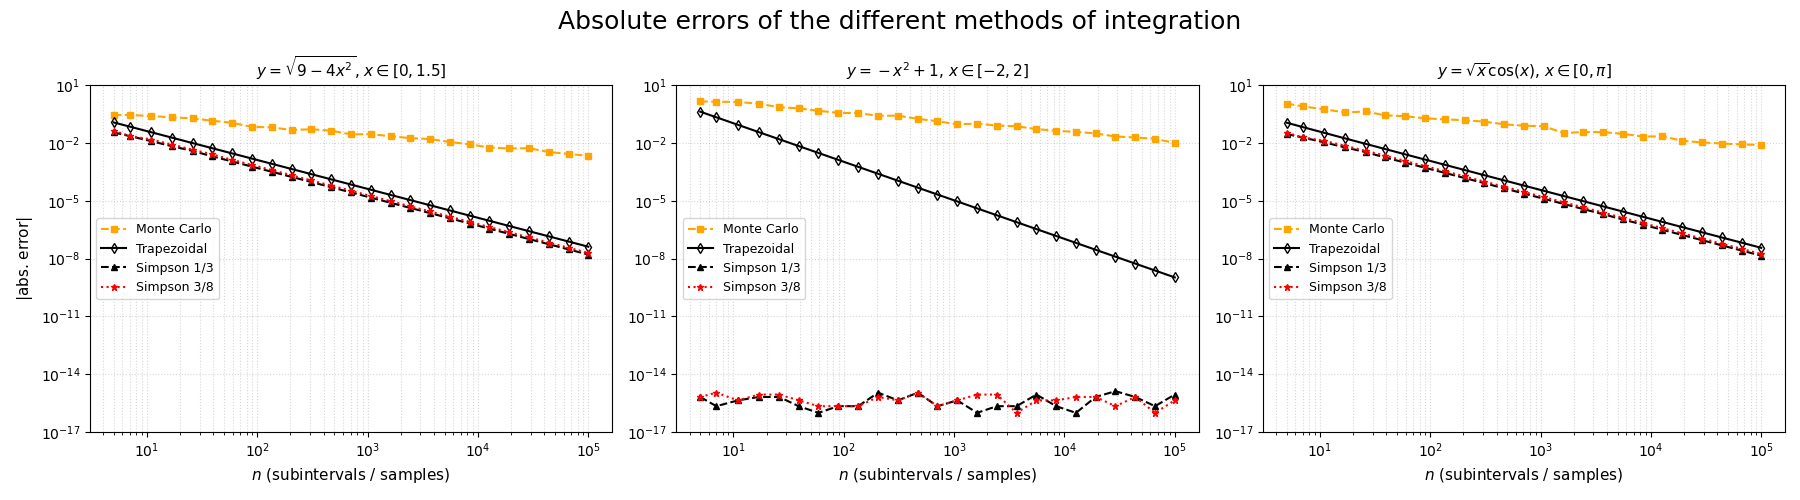

Figure 1 shows the absolute error relative to ```scipy.integrate.quad()``` of the four functions; $y = \sqrt{9-4x^2}, x=0, x=3/2$, $y = -x^2 + 1, x=-2, x=2$, and $ y = \sqrt{x}\cos{x}, x=0, x=\pi $.

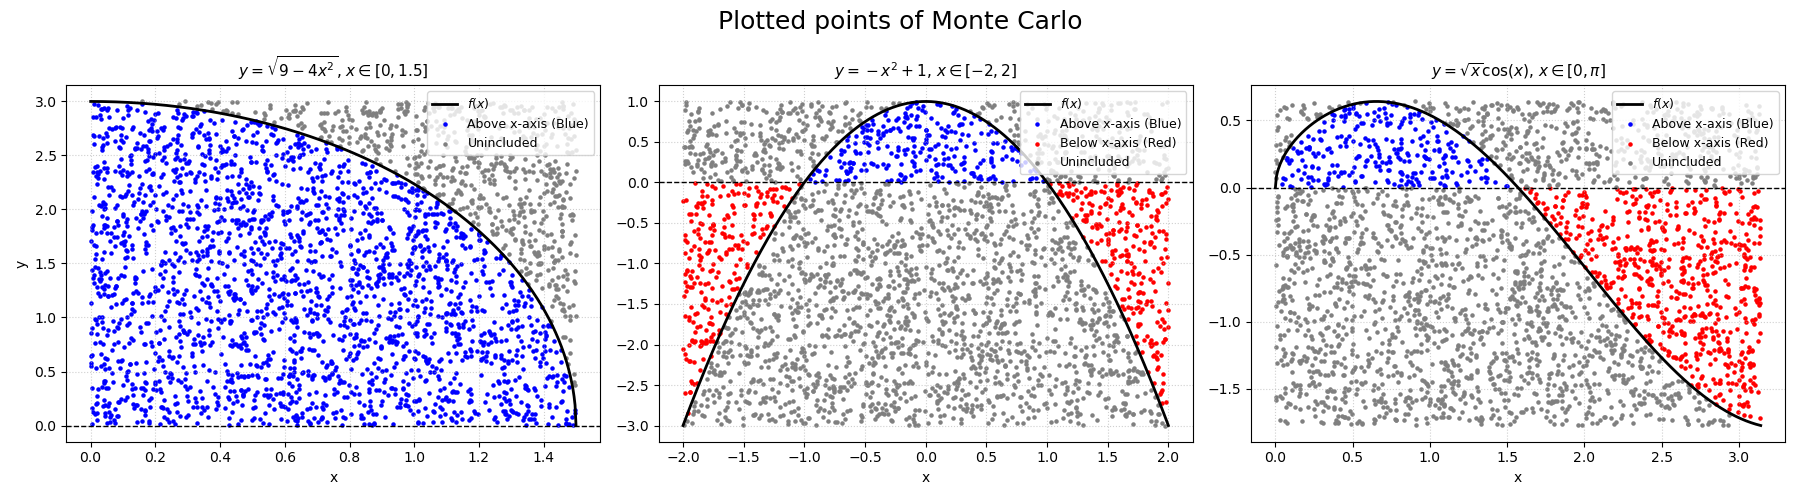

Figure 2 plots the random points used in the Monte Carlo simulation. The point is blue if it is bounded by the function and is above the x-axis, otherwise, red if it is bounded by the function and below the x-axis. As number of points increases, the area under the curve within a range gets more accurate.


### Report discussion

- Explain the figures.

In Figure 1 (left) we see that all the grid (Trapezoidal, Simpson's rule) methods have identical slopes. This is because the derivative of $y = \sqrt{9-4x^2}, x=0, x=3/2$, $y^{'} = \frac{-4x}{\sqrt{9-4x^2}}$ tends toward negative infinity at $x = 1.5$. This shows that methods like Trapezoidal and Simpson's rule  rely on the boundedness of the higher derivatives to achieve high accuracy. Since the tangent at the boundary is vertical, these methods will converge similarly, which explains the identical slopes. Monte Carlo is the slowest one with a convergence rate of $\mathcal{O}(n^{-0.5})$.

In Figure 1 (center), the function is nicely smooth. Both Simpson's methods have the lowest absolute error near machine precision. Both the aformentioned methods use parabolic segments so it is exact for a polynomial of degree 2, so it must be the most accurate methods. Trapezoidal method uses linear segments and we see that it follows a linear descent (theoretically, $\mathcal{O}(n^{-2})$) and Monte-Carlo remains the slowest.

In Figure 1 (right), we have another vertical tangent but this time at x = 0, so it behaves similar to (left).

- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?

Monte Carlo Simulation utilizes the law of large numbers. over a range $[a, b]$, the expectation value of a function $f(x)$ is $\langle f \rangle = \frac{1}{b-a}\int_a^bf(x) dx$. Isolating the integral gets us $I = (b-a)\langle f \rangle = (b-a) \frac{1}{N} \sum^N_{i=1} f(x_i)$. As N approaches infinity, the sample mean of the randomly sampled points converges to the true expected value, this however, is slow. Newton-Cotes methods perform better for smooth and continuous integrand functions because it uses linear (Trapezoidal) or parabolic (Simpson's) approximations that can match such functions. Furthermore, more complex functions may favor Monte Carlo method because its accuracy is not dependent on smoothness and continuity of function.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as integrate
import math

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 

**Report discussion**: 
- Explain the figures.

- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?

In [2]:
# our funcs

def f1(x):
    return np.sqrt(9 - 4*x**2)

def f2(x):
    return -x**2 + 1

def f3(x):
    return np.sqrt(x) * np.cos(x)
    
'''
# benchmark:
result, error = integrate.quad(f1, 0, 3/2)
print(result)
'''

# integration methods

def monteCarloIntegration(func, lower_bnd, upper_bnd, samples = int(1e4)):
    xs = np.random.uniform(lower_bnd, upper_bnd, samples)
    fx = func(xs)
    avg_fx = np.mean(fx) # take the average height of the function
    return (upper_bnd-lower_bnd) * avg_fx # area under the curve: length x height

def trapezoidalIntegration(func, lower_bnd, upper_bnd, samples = int(1e4)):

    N = max(1, samples-1)
    samples = N + 1
    step_size = (upper_bnd - lower_bnd) / N # get the step size first

    
    xs = np.linspace(lower_bnd, upper_bnd, samples)
    coeffs = np.ones(samples) # instead of looping, make use of the pattern of the coefficients
    coeffs[0] = 0.5 # half at the bounds
    coeffs[-1] = 0.5
    contributions = coeffs * func(xs) # sum it all by multiplying the coefficients to the evaluated function
    return step_size*np.sum(contributions)

def simpsonIntegrationOneThirds(func, lower_bnd, upper_bnd, samples = int(1e4)-1):
    
    #assert (samples-1) % 2 == 0, "subintervals must be a multiple of 2" # this is in place for the simpson's 1/3 
    # insetad of asserting, make it so that any sample will just be adjusted if not mult of 2
    N = max(2, samples -1)
    if N % 2 != 0:
        N += 1
    samples = N + 1 # adjust to nearest number if subdivisions aren't divisible by 2

    
    step_size = (upper_bnd - lower_bnd) / N # step size first
    xs = np.linspace(lower_bnd, upper_bnd, samples)
    coeffs = 2 * np.ones(samples) # same thing, don't loop and use vectorized functions
    coeffs[1::2] = 4 # make use of the pattern
    coeffs[0] = 1
    coeffs[-1] = 1
    contributions = coeffs * func(xs)
    return (step_size/3) * np.sum(contributions)

def simpsonIntegrationThreeEights(func, lower_bnd, upper_bnd, samples = int(1e4)):
    #assert (samples-1) % 3 == 0, "subintervals must be a multiple of 3" # this in place for the simpson's 3/8
    # instead of asserting, make it so that any sample will just be adjusted if not mult of 3
    N = max(3, samples - 1)
    if remainder := N % 3:
        N += (3 - remainder) # adjust N to nearest multiple of 3
    samples = N + 1
    
    step_size = (upper_bnd - lower_bnd) / N # same ting as the other functions
    xs = np.linspace(lower_bnd, upper_bnd, samples)
    coeffs = 3 * np.ones(samples)
    coeffs[3::3] = 2
    coeffs[0] = 1
    coeffs[-1] = 1
    contributions = coeffs * func(xs)
    return (3 * step_size/8) * np.sum(contributions)

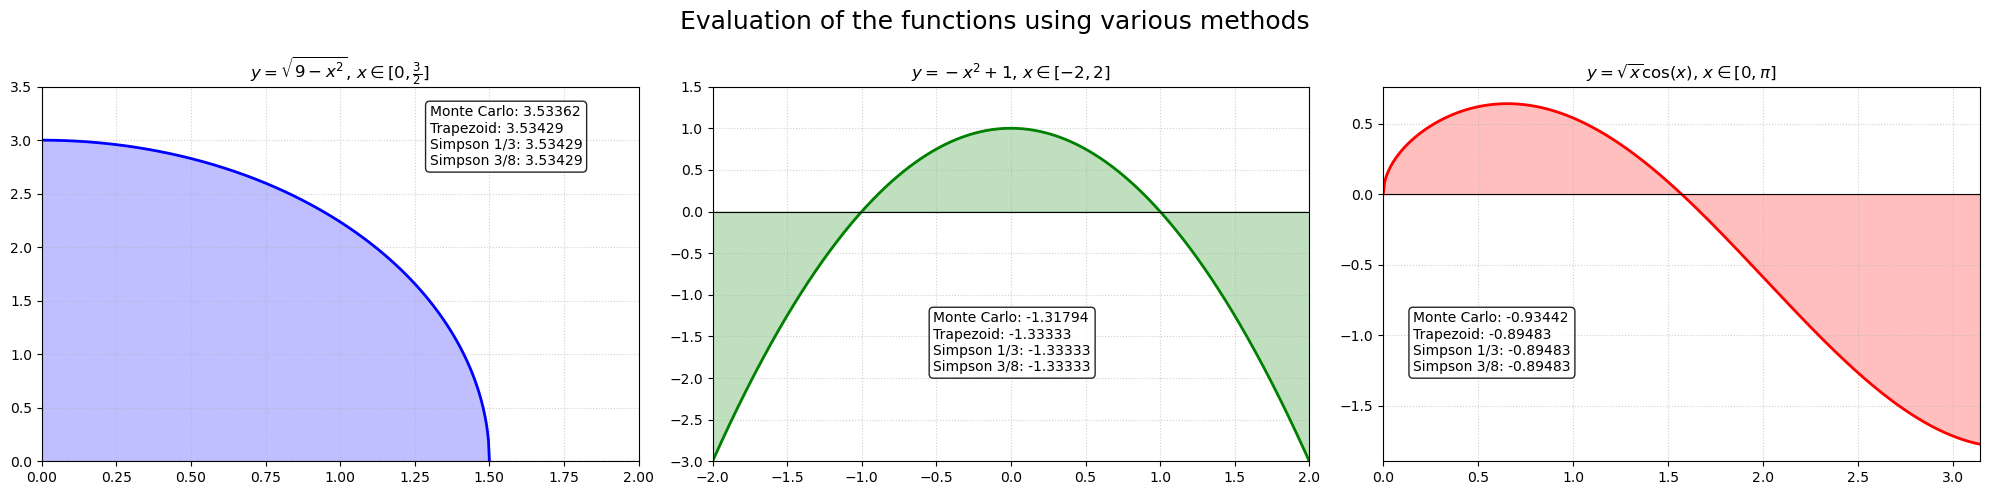

In [3]:
# plotting
fig, axs = plt.subplots(1,3, figsize = (20, 5))

# f1
xs_1 = np.linspace(0, 1.5, 500, endpoint=True)
fxs_1 = f1(xs_1)
# different integration methods
mc_1 = monteCarloIntegration(f1, 0, 1.5)
tr_1 = trapezoidalIntegration(f1, 0, 1.5)
sot_1 = simpsonIntegrationOneThirds(f1, 0, 1.5)
ste_1 = simpsonIntegrationThreeEights(f1, 0, 1.5)

# plot
axs[0].plot(xs_1, fxs_1, color='blue', linewidth=2)
axs[0].fill_between(xs_1, 0, fxs_1, color='blue', alpha=0.25)
axs[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
axs[0].set_xlim(0, 2)
axs[0].set_ylim(0, 3.5)
axs[0].set_title(r"$y = \sqrt{9 - x^2}$, $x \in [0,\frac{3}{2}]$")

textstr_1 = f"Monte Carlo: {mc_1:.5f}\nTrapezoid: {tr_1:.5f}\nSimpson 1/3: {sot_1:.5f}\nSimpson 3/8: {ste_1:.5f}"
axs[0].text(0.65, 0.95, textstr_1, transform=axs[0].transAxes, fontsize=10, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

# f2
xs_2 = np.linspace(-2, 2, 500, endpoint=True)
fxs_2 = f2(xs_2)
# different integration methods
mc_2 = monteCarloIntegration(f2, -2, 2)
tr_2 = trapezoidalIntegration(f2, -2, 2)
sot_2 = simpsonIntegrationOneThirds(f2, -2, 2)
ste_2 = simpsonIntegrationThreeEights(f2, -2, 2)

# plot
axs[1].plot(xs_2, fxs_2, color='green', linewidth=2)
axs[1].fill_between(xs_2, 0, fxs_2, color='green', alpha=0.25)
axs[1].axhline(0, color='black', linewidth=0.8)
axs[1].set_xlim(-2, 2)
axs[1].set_ylim(-3, 1.5)
axs[1].set_title(r"$y = -x^2 + 1$, $x \in [-2,2]$")

textstr_2 = f"Monte Carlo: {mc_2:.5f}\nTrapezoid: {tr_2:.5f}\nSimpson 1/3: {sot_2:.5f}\nSimpson 3/8: {ste_2:.5f}"
axs[1].text(0.37, 0.40, textstr_2, transform=axs[1].transAxes, fontsize=10, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

# f3
xs_3 = np.linspace(0, np.pi, 500, endpoint=True)
fxs_3 = f3(xs_3)
# different integration methods
mc_3 = monteCarloIntegration(f3, 0, np.pi)
tr_3 = trapezoidalIntegration(f3, 0, np.pi)
sot_3 = simpsonIntegrationOneThirds(f3, 0, np.pi)
ste_3 = simpsonIntegrationThreeEights(f3, 0, np.pi)

# plot
axs[2].plot(xs_3, fxs_3, color='red', linewidth=2)
axs[2].fill_between(xs_3, 0, fxs_3, color='red', alpha=0.25)
axs[2].axhline(0, color='black', linewidth=0.8)
axs[2].set_xlim(0, np.pi)
axs[2].set_title(r"$y = \sqrt{x}\cos(x)$, $x \in [0, \pi]$")

textstr_3 = f"Monte Carlo: {mc_3:.5f}\nTrapezoid: {tr_3:.5f}\nSimpson 1/3: {sot_3:.5f}\nSimpson 3/8: {ste_3:.5f}"
axs[2].text(0.05, 0.40, textstr_3, transform=axs[2].transAxes, fontsize=10, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

for ax in axs:
    ax.grid(True, linestyle=':', alpha=0.6)

fig.suptitle("Evaluation of the functions using various methods", fontsize = 18)
plt.tight_layout()
plt.savefig("areas.png")

plt.show()

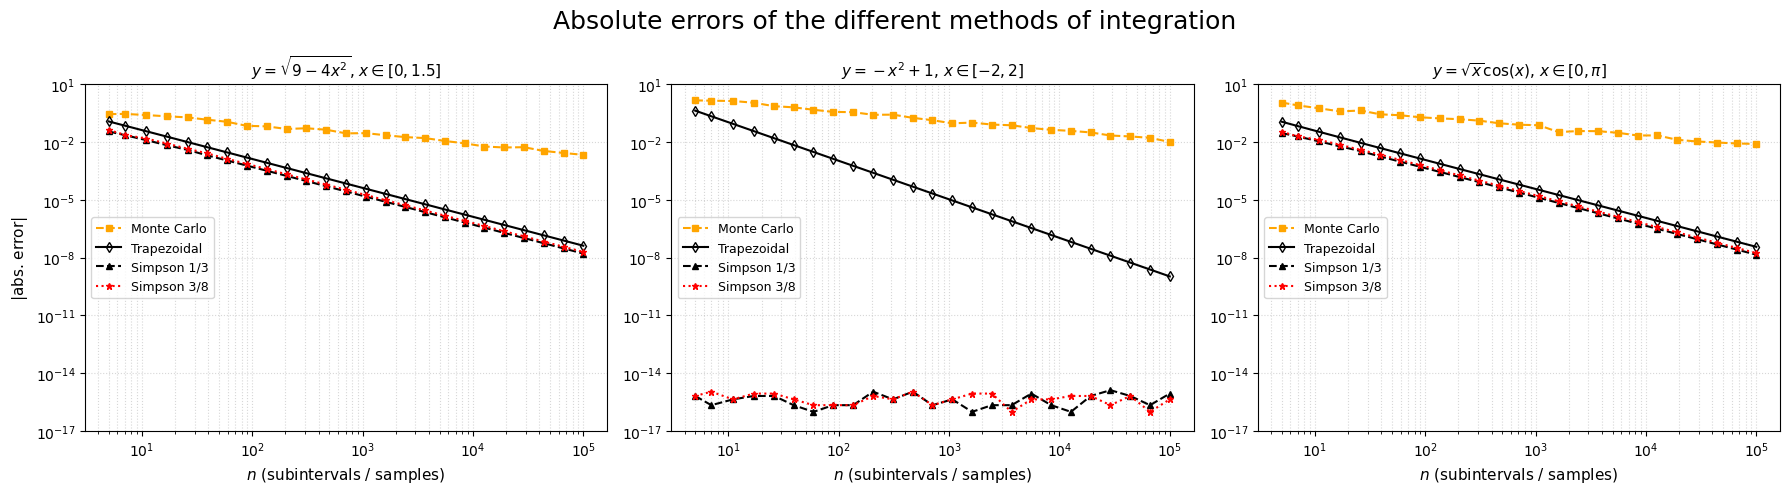

In [4]:
# error against scipy.integrate.quad

# put our args in an array so its loopable
functions = [
    (f1, 0.0, 1.5, r"$y = \sqrt{9 - 4x^2}$, $x \in [0, 1.5]$"),
    (f2, -2.0, 2.0, r"$y = -x^2 + 1$, $x \in [-2, 2]$"),
    (f3, 0.0, np.pi, r"$y = \sqrt{x}\cos(x)$, $x \in [0, \pi]$")
]

fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# error against scipy.integrate.quad
n_vals = np.unique(np.logspace(0.7, 5, 25, dtype = int)) # use np.unique to remove duplicate values since we're going to use integers
monte_carlo_trials = 30 # multiple trials then just average to get error

# loop for each set of args in function
for idx, (func, a, b, title) in enumerate(functions):

    # keep it all here all here all here i jbcs
    err_mc, err_trap, err_simp13, err_simp38 = [], [], [], []

    exact_val, _ = integrate.quad(func, a, b)

    for n in n_vals:
        samples = n+1

        # newton-cotes methods 
        val_trap = trapezoidalIntegration(func, a, b, samples)
        val_simp13 = simpsonIntegrationOneThirds(func, a, b, samples)
        val_simp38 = simpsonIntegrationThreeEights(func, a, b, samples)

        # monte carlo method
        mc_runs = [monteCarloIntegration(func, a, b, samples) for j in range(monte_carlo_trials)]
        mean_mc_err = np.mean([abs(result - exact_val) for result in mc_runs]) # average error over the trials

        # simpler to calculate the error for newton-cotes methods
        err_trap.append(max(abs(val_trap - exact_val), 1e-16))
        err_simp13.append(max(abs(val_simp13 - exact_val), 1e-16))
        err_simp38.append(max(abs(val_simp38 - exact_val), 1e-16))
        err_mc.append(max(mean_mc_err, 1e-16))

    # plotting
    ax = axs[idx]
    ax.loglog(n_vals, err_mc, 's--', color='orange', markersize=4, label='Monte Carlo')
    ax.loglog(n_vals, err_trap, 'kd-', markersize=5, fillstyle='none', label='Trapezoidal')
    ax.loglog(n_vals, err_simp13, 'k^--', markersize=5, label='Simpson 1/3')
    ax.loglog(n_vals, err_simp38, 'r*:', markersize=5, label='Simpson 3/8')
    
    ax.set_xlabel(r'$n$ (subintervals / samples)', fontsize=11)
    if idx == 0:
        ax.set_ylabel(r'$|\text{abs. error}|$', fontsize=11)
    ax.set_ylim(10**-17, 10**1)
    ax.set_title(title, fontsize=11)
    ax.grid(True, which="both", linestyle=":", alpha=0.5)
    ax.legend(fontsize=9, loc='center left')

fig.suptitle("Absolute errors of the different methods of integration", fontsize = 18)
plt.tight_layout()
plt.savefig("abserrors.png")
plt.show()

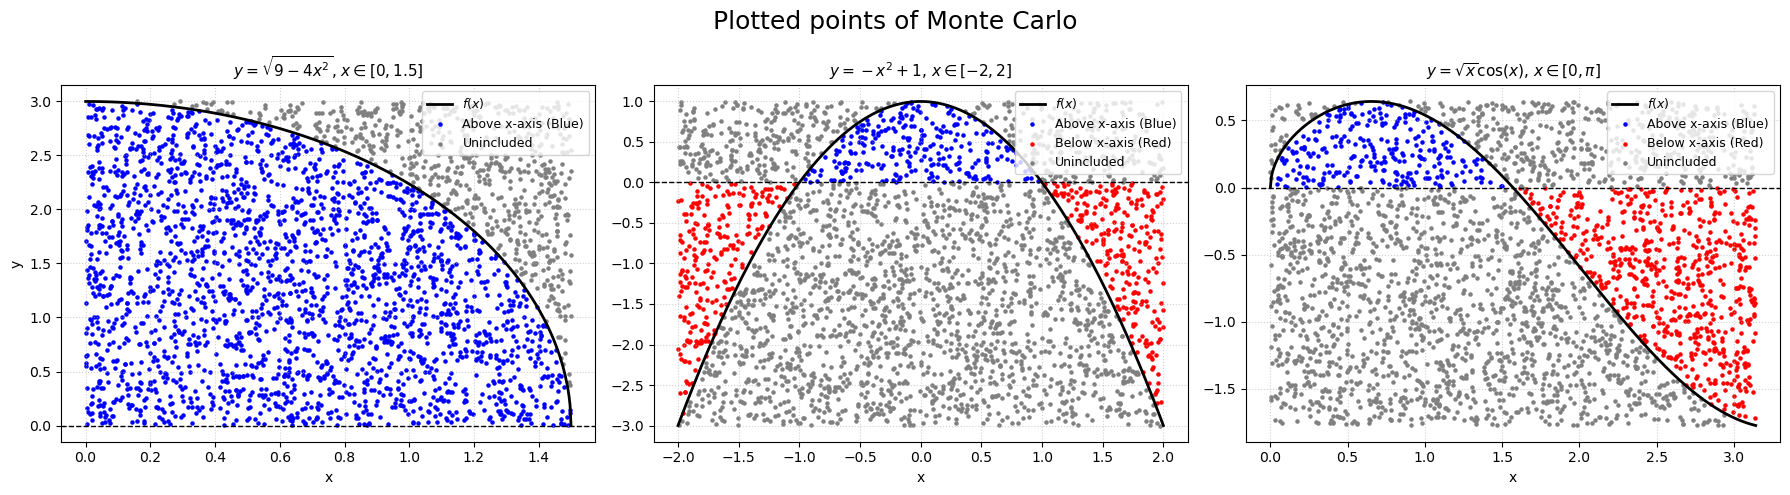

In [5]:
num_mc_points = 3000
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# iterate through all functions
for idx, (func, a, b, title) in enumerate(functions):
    ax = axs[idx]
    
    xs_curve = np.linspace(a, b, 500) # generate smooth curve for reference
    ys_curve = func(xs_curve)
    
    # define bounding box dimensions: [a, b] x [y_min, y_max]
    y_min = min(0.0, np.min(ys_curve))
    y_max = max(0.0, np.max(ys_curve))
    
    # sample random 2D points in the bounding box
    mc_x = np.random.uniform(a, b, num_mc_points)
    mc_y = np.random.uniform(y_min, y_max, num_mc_points)
    
    f_x = func(mc_x) # vvaluate function values at randomly sampled x positions
    
    # filter points bounded between the curve and the x-axis
    mask_above = (mc_y >= 0) & (mc_y <= f_x) & (f_x >= 0)  # points above x-axis
    mask_below = (mc_y < 0) & (mc_y >= f_x) & (f_x < 0)  # points below x-axis
    mask_unincluded_above = (mc_y > f_x) & (mc_y > 0) # unincluded above x-axis
    mask_unincluded_below = (mc_y < f_x) & (mc_y < 0) # unincluded below x-axis
    
    # plot function curve and baseline x-axis
    ax.plot(xs_curve, ys_curve, color='black', linewidth=2, label=r'$f(x)$')
    ax.axhline(0, color='black', linewidth=1, linestyle='--')
    
    # plot bounded points
    if np.any(mask_above):
        ax.scatter(mc_x[mask_above], mc_y[mask_above], color='blue', s=5, label='Above x-axis (Blue)')
    if np.any(mask_below):
        ax.scatter(mc_x[mask_below], mc_y[mask_below], color='red', s=5, label='Below x-axis (Red)')
    if np.any(mask_unincluded_above):
        ax.scatter(mc_x[mask_unincluded_above], mc_y[mask_unincluded_above], color = 'gray', s=5, label='Unincluded')
    if np.any(mask_unincluded_below):
        ax.scatter(mc_x[mask_unincluded_below], mc_y[mask_unincluded_below], color = 'gray', s=5)
        
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('x', fontsize=10)
    if idx == 0:
        ax.set_ylabel('y', fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='best', fontsize=9)

fig.suptitle("Plotted points of Monte Carlo", fontsize = 18)
plt.tight_layout()
plt.savefig("plottedpoints.png")
plt.show()